# Phase 1 Main Pipeline: Automated Sleep Staging & Wearable EEG Channel Simulation

This notebook implements and executes the complete **Phase 1 Pipeline** step by step on the 10 **SHHS1** Polysomnography (PSG) recordings in `data/raw/`:

1. **Step 1 — Data Ingestion & Standardized Preprocessing** (`src/data/preprocessing.py`)
   - Reads `.edf` physiological signals (`EEG` = `C4-A1`, `EEG(sec)` = `C3-A2`, `EOG(L)`, `EOG(R)`, `EMG`) and Compumedics Profusion `.xml` annotations.
   - Maps sleep stages to the 5 AASM classes (`0: Wake`, `1: N1`, `2: N2`, `3: N3 [merges R&K stages 3 & 4]`, `4: REM`).
   - Applies a 60 Hz notch filter, polyphase resampling to **100 Hz**, zero-phase **5th-order Butterworth bandpass filtering (0.2–49 Hz)**, and segmentation into **30-second epochs** (`3000` samples/epoch).
2. **Step 2 — Channel Ablation & Wearable Simulation** (`src/data/channel_sim.py`)
   - **Category A (Clinical Baselines):** `full_psg` (`5ch`), `eeg_eog` (`4ch`), `dual_eeg` (`2ch`).
   - **Category B (Option 1 — Location-Close Proxies):** `single_eeg_c4` (`C4-A1`), `single_eeg_c3` (`C3-A2`), `single_eog_l` (`EOG(L)` near `AF7/Fp1`), `dual_eog` (`EOG(L), EOG(R)`).
   - **Category C (Option 2 — Mathematical Wearable Derivations):**
     - `sim_bipolar_eog`: $\text{EOG(L)} - \text{EOG(R)}$ (Mastoid-free cross-forehead/temple strip `AF7-AF8` / `Fp1-Fp2`).
     - `sim_avg_eog`: $\frac{\text{EOG(L)} + \text{EOG(R)}}{2}$ (Mastoid-referenced midline forehead sensor `Fpz-M2`).
     - `sim_bipolar_eeg`: $(\text{C3-A2}) - (\text{C4-A1})$ (Cross-hemisphere bipolar subtraction, testing bilateral slow-wave cancellation).
     - `sim_avg_eeg`: $\frac{(\text{C3-A2}) + (\text{C4-A1})}{2}$ (Mastoid-referenced midline central sensor).
     - `sim_eeg_minus_eog`: $(\text{C4-A1}) - \text{EOG(L)}$ (Mastoid-free fronto-central differential).
3. **Step 3 — TinySleepNet Architecture** (`src/models/tinysleepnet.py`)
   - Modular PyTorch implementation supporting **Model A (`use_context=False`, Context-Blind CNN)** and **Model B (`use_context=True`, Context-Aware CNN + Unidirectional LSTM)** via a single boolean toggle.
4. **Step 4 — Subject-Independent 10-Fold Cross-Validation Trainer** (`src/training/trainer.py`)
   - Strict subject-level 80% Train / 10% Validation / 10% Test splits saved to `data/splits/shhs_10fold_splits.json`.
5. **Step 5 — Standardized Evaluation Framework** (`src/evaluation/metrics.py` & `src/evaluation/clinical_sleep.py`)
   - Exact **Markov et al. (2025)** Equations 1–29 (Multiclass $\kappa$, Multiclass MCC, Micro/Macro/Per-Stage ACC, SE, SP, PPV, NPV, F1), Normalized Confusion Matrices, Whole-Night Clinical Sleep Parameters (`TST`, `SE%`, `SOL`, `WASO`), Hypnograms, and **Bland–Altman** plots.

---
## Step 0: Install `requirements.txt` & Verify All Required Libraries

This first cell ensures all packages listed in `requirements.txt` (`mne`, `pyedflib`, `pypdf`, `pymupdf`, `torch`, `numpy`, `scipy`, `scikit-learn`, `pandas`, `matplotlib`, `seaborn`, `pyyaml`, `tqdm`, `h5py`) are installed in the active notebook kernel before running the pipeline.

In [1]:
import importlib
import shutil
import subprocess
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "requirements.txt").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

req_file = PROJECT_ROOT / "requirements.txt"
print(f"Installing dependencies from {req_file} into kernel: {sys.executable}")
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(req_file)])

# If running on an NVIDIA GPU / DGX Spark (`nvidia-smi` present), ensure CUDA-enabled PyTorch (cu128 for Blackwell sm_120) is active
import torch
if shutil.which("nvidia-smi") is not None and not torch.cuda.is_available():
    print("NVIDIA GPU detected via nvidia-smi, but CPU-only PyTorch is installed. Installing CUDA PyTorch (cu128)...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--upgrade", "--force-reinstall",
        "torch", "--index-url", "https://download.pytorch.org/whl/cu128"
    ])
    print("CUDA PyTorch installed! Please restart the Jupyter kernel once so the new CUDA libraries load.")

REQUIRED_MODULES = [
    ("mne", "mne"),
    ("pyedflib", "pyedflib"),
    ("pypdf", "pypdf"),
    ("pymupdf", "fitz"),
    ("torch", "torch"),
    ("numpy", "numpy"),
    ("scipy", "scipy"),
    ("scikit-learn", "sklearn"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("seaborn", "seaborn"),
    ("pyyaml", "yaml"),
    ("tqdm", "tqdm"),
    ("h5py", "h5py"),
]

print("\nVerified Installed Libraries:")
for pkg_name, mod_name in REQUIRED_MODULES:
    mod = importlib.import_module(mod_name)
    ver = getattr(mod, "__version__", "installed")
    print(f"  - {pkg_name:15s} ({mod_name}): {ver}")

Installing dependencies from /home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation/requirements.txt into kernel: /home/uclab-guest-thesis/.Samuel_venv/bin/python

Verified Installed Libraries:
  - mne             (mne): 1.13.2
  - pyedflib        (pyedflib): 0.1.42
  - pypdf           (pypdf): 7.0.1
  - pymupdf         (fitz): 2.1
  - torch           (torch): 2.11.0+cu128
  - numpy           (numpy): 2.5.4
  - scipy           (scipy): 1.18.1


/home/uclab-guest-thesis/.Samuel_venv/lib/python3.12/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


  - scikit-learn    (sklearn): 1.9.1
  - pandas          (pandas): 3.0.6
  - matplotlib      (matplotlib): 3.11.2
  - seaborn         (seaborn): 0.13.2
  - pyyaml          (yaml): 6.0.3
  - tqdm            (tqdm): 4.70.1
  - h5py            (h5py): 3.16.0


In [2]:
import os
import sys
from pathlib import Path

import yaml
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is on sys.path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "configs").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.preprocessing import (
    select_shhs_cohort,
    download_and_preprocess_shhs_cohort,
    preprocess_all_recordings,
    load_preprocessed_subject,
    materialize_subject_record,
    AASM_STAGE_NAMES,
)
from src.data.channel_sim import (
    load_ablation_configs,
    apply_channel_config,
    is_channel_config_compatible,
)
from src.data.dataset import (
    SleepStageDataset,
    ensure_subject_cv_splits,
    generate_subject_cv_splits,
    load_subject_cv_splits,
    load_subject_records_from_dir,
)
from src.models.tinysleepnet import TinySleepNet, build_tinysleepnet_from_config
from src.training.trainer import (
    run_cross_validation_for_config,
    load_saved_ablation_results,
    get_experiment_results_dir,
    resolve_device,
    get_device_description,
)
from src.evaluation.metrics import (
    compute_all_epoch_metrics,
    metrics_summary_to_dataframe,
    plot_normalized_confusion_matrix,
)
from src.evaluation.clinical_sleep import (
    compute_hypnogram_parameters,
    compute_bland_altman_agreement,
    plot_bland_altman_grid,
    plot_hypnogram_comparison,
)

with open(PROJECT_ROOT / "configs/base_config.yaml", "r", encoding="utf-8") as f:
    base_config = yaml.safe_load(f)

shhs_configs = load_ablation_configs(PROJECT_ROOT / "configs/ablation_channels.yaml", section="shhs_configs")
full_10_20_configs = load_ablation_configs(PROJECT_ROOT / "configs/ablation_channels.yaml", section="full_10_20_configs")

active_device = resolve_device(base_config["training"]["device"])
print(f"Project Root : {PROJECT_ROOT}")
print(f"PyTorch      : {torch.__version__} | Device: {get_device_description(active_device)}")
print(f"SHHS Configs : {len(shhs_configs)} loaded ({list(shhs_configs.keys())})")

Project Root : /home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation
PyTorch      : 2.11.0+cu128 | Device: cuda (NVIDIA GB10)
SHHS Configs : 12 loaded (['full_psg', 'eeg_eog', 'dual_eeg', 'single_eeg_c4', 'single_eeg_c3', 'single_eog_l', 'dual_eog', 'sim_bipolar_eog', 'sim_avg_eog', 'sim_bipolar_eeg', 'sim_avg_eeg', 'sim_eeg_minus_eog'])


---
## Step 1: Cohort Selection, NSRR Per-Patient Download & 4-Channel `float16` Preprocessing (`src/data/preprocessing.py`)

1. **Cohort Filter (`cohort_filter` in `configs/base_config.yaml`):**
   - Selects **healthy patients only** (`ahi_a0h3 < 5.0` and `rdi3p < 5.0` events/hour -> **`1,771` subjects** in SHHS1).
   - Signal quality and duration filters (`min_recording_hours`, `min_usable_eeg_hours`, `min_eeg_quality_rating`, `min_eog_quality_rating`, `exclude_abnormal_eeg`) are included in `configs/base_config.yaml` and ready to toggle, but disabled (`0` / `1` / `false`) for the initial full-cohort baseline.
2. **Automated Per-Patient NSRR Download & `float16` Storage:**
   - Put your NSRR token in `.nsrr_token` in the project root (or set `NSRR_TOKEN` below; `.nsrr_token` is excluded from Git via `.gitignore`).
   - For each subject not yet in `data/processed/`, the pipeline downloads `{subject_id}.edf` and `{subject_id}-profusion.xml` from `sleepdata.org`, extracts the 4 EEG+EOG channels (`[C4-A1, C3-A2, EOG(L), EOG(R)]`), filters & resamples to `100 Hz`, saves `data/processed/{subject_id}.npz` in `float16` (`~23 MB`/subject, `~40 GB` total for all 1,771 subjects), and deletes the temporary raw `.edf` file.
   - If interrupted, re-running this cell skips all already-preprocessed `.npz` files.

In [3]:
# Optional: Paste your NSRR token string here, or save it in a local `.nsrr_token` file in the project root
NSRR_TOKEN = None

selected_subject_ids, df_cohort_meta = select_shhs_cohort(base_config, root_dir=PROJECT_ROOT)
print(f"Selected SHHS1 Cohort: {len(selected_subject_ids):,} subjects (saved metadata to data/splits/shhs1_selected_cohort.csv)")

saved_npz_paths, skipped_subject_ids = download_and_preprocess_shhs_cohort(
    config=base_config,
    subject_ids=selected_subject_ids,
    root_dir=PROJECT_ROOT,
    nsrr_token=NSRR_TOKEN,
    overwrite=False,
    verbose=True,
)

all_records = load_subject_records_from_dir(
    PROJECT_ROOT / base_config["paths"]["processed_dir"],
    subject_ids=selected_subject_ids,
)

summary_rows = []
for rec in all_records:
    labels = rec["labels"]
    row = {
        "Subject_ID": rec["subject_id"],
        "N_Epochs": len(labels),
        "Duration_Hours": round(len(labels) * 30.0 / 3600.0, 2),
        "Channels": ", ".join(rec["channel_names"]),
    }
    for idx, st_name in enumerate(AASM_STAGE_NAMES):
        row[f"{st_name}_epochs"] = int((labels == idx).sum())
    summary_rows.append(row)

df_subjects = pd.DataFrame(summary_rows)
display(df_subjects.head(15))
print(f"Loaded {len(all_records):,} subjects | Total 30s epochs: {df_subjects['N_Epochs'].sum():,}")

Selected SHHS1 Cohort: 1,771 subjects (saved metadata to data/splits/shhs1_selected_cohort.csv)
  [Local SHHS1 Mirror Detected] Reading EDFs from /data/shhs/polysomnography/edfs/shhs1 with 8 parallel CPU workers!


Error preprocessing subject shhs1-200279: /home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation/data/raw/edf/shhs1-200279.edf: the file is not EDF(+) or BDF(+) compliant (it contains format errors); skipping.


  [  87/1771] shhs1-200279: PREPROCESS ERROR (/home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation/data/raw/edf/shhs1-200279.edf: the file is not EDF(+) or BDF(+) compliant (it contains format errors)) -> skipped.


Error preprocessing subject shhs1-201115: /home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation/data/raw/edf/shhs1-201115.edf: the file is not EDF(+) or BDF(+) compliant (it contains format errors); skipping.


  [ 372/1771] shhs1-201115: PREPROCESS ERROR (/home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation/data/raw/edf/shhs1-201115.edf: the file is not EDF(+) or BDF(+) compliant (it contains format errors)) -> skipped.


Error preprocessing subject shhs1-202248: /home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation/data/raw/edf/shhs1-202248.edf: the file is not EDF(+) or BDF(+) compliant (it contains format errors); skipping.


... (3 outputs left out)

Error preprocessing subject shhs1-204217: /home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation/data/raw/edf/shhs1-204217.edf: the file is not EDF(+) or BDF(+) compliant (it contains format errors); skipping.


  [1278/1771] shhs1-204217: PREPROCESS ERROR (/home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation/data/raw/edf/shhs1-204217.edf: the file is not EDF(+) or BDF(+) compliant (it contains format errors)) -> skipped.
Cohort preprocessing summary: 1766/1771 subjects ready (cached=1766, newly_processed=0, skipped=5).
  [Cohort Channel Filter] Excluded 28/1766 subjects missing C3-A2 -> 1738 complete 4-channel subjects retained.


,Subject_ID,N_Epochs,Duration_Hours,Channels,Wake_epochs,N1_epochs,N2_epochs,N3_epochs,REM_epochs
0,shhs1-200001,1084,9.03,"C4-A1, C3-A2, EOG(L), EOG(R)",333,47,457,145,102
1,shhs1-200004,875,7.29,"C4-A1, C3-A2, EOG(L), EOG(R)",273,18,177,315,92
2,shhs1-200008,959,7.99,"C4-A1, C3-A2, EOG(L), EOG(R)",288,15,362,213,81
3,shhs1-200010,1084,9.03,"C4-A1, C3-A2, EOG(L), EOG(R)",251,11,491,163,168
4,shhs1-200017,950,7.92,"C4-A1, C3-A2, EOG(L), EOG(R)",215,13,473,63,186
5,shhs1-200019,1086,9.05,"C4-A1, C3-A2, EOG(L), EOG(R)",627,3,265,138,53
6,shhs1-200021,1072,8.93,"C4-A1, C3-A2, EOG(L), EOG(R)",397,98,373,82,122
7,shhs1-200033,360,3.00,"C4-A1, C3-A2, EOG(L), EOG(R)",170,11,102,59,18
8,shhs1-200034,869,7.24,"C4-A1, C3-A2, EOG(L), EOG(R)",238,8,288,259,76
9,shhs1-200036,989,8.24,"C4-A1, C3-A2, EOG(L), EOG(R)",194,56,531,28,180


Loaded 1,738 subjects | Total 30s epochs: 1,761,352


---
## Step 2: Channel Ablation & Mathematical Wearable Simulation (`src/data/channel_sim.py`)

Let's inspect the compatible SHHS1 channel configurations and verify the shapes and biophysical properties of the simulated channels (comparing mastoid-referenced bilateral averaging vs. mastoid-free bipolar subtraction on an N3 Slow-Wave Sleep epoch).

In [4]:
sample_subj = materialize_subject_record(all_records[0])
shhs_configs = {
    k: v
    for k, v in shhs_configs.items()
    if is_channel_config_compatible(sample_subj["channel_names"], v)
}
config_inspection_rows = []

for cfg_name, cfg_spec in shhs_configs.items():
    derived_x, ch_names = apply_channel_config(sample_subj, cfg_spec, normalize=True)
    config_inspection_rows.append({
        "Config_Name": cfg_name,
        "Category": cfg_spec.get("category", ""),
        "Mastoid_Ref": cfg_spec.get("mastoid", False),
        "Out_Shape": str(derived_x.shape),
        "Derived_Channels": ", ".join(ch_names),
        "Description": cfg_spec.get("description", ""),
    })

df_configs = pd.DataFrame(config_inspection_rows)
display(df_configs)

,Config_Name,Category,Mastoid_Ref,Out_Shape,Derived_Channels,Description
0,eeg_eog,clinical_baseline,True,"(1084, 4, 3000)","C4-A1, C3-A2, EOG(L), EOG(R)","4-ch EEG + EOG without chin EMG (C4-A1, C3-A2,..."
1,dual_eeg,clinical_baseline,True,"(1084, 2, 3000)","C4-A1, C3-A2","2-ch Bilateral Central EEG (C4-A1, C3-A2)"
2,single_eeg_c4,location_proxy,True,"(1084, 1, 3000)",C4-A1,1-ch Central EEG C4-A1 (Standard SHHS single-l...
3,single_eeg_c3,location_proxy,True,"(1084, 1, 3000)",C3-A2,1-ch Central EEG C3-A2 (Waters & Clifford 2022...
4,single_eog_l,location_proxy,True,"(1084, 1, 3000)",EOG(L),1-ch Left EOG (Eye-mask/temple/forehead wearab...
5,dual_eog,location_proxy,True,"(1084, 2, 3000)","EOG(L), EOG(R)",2-ch Bilateral EOG (Two-channel forehead/eye-m...
6,sim_bipolar_eog,math_simulation,False,"(1084, 1, 3000)",Sim_EOG_Bipolar,1-ch Simulated cross-forehead/temple bipolar s...
7,sim_avg_eog,math_simulation,True,"(1084, 1, 3000)",Sim_EOG_Avg,1-ch Simulated midline forehead/periorbital se...
8,sim_bipolar_eeg,math_simulation,False,"(1084, 1, 3000)",Sim_EEG_Bipolar,1-ch Simulated cross-hemisphere bipolar EEG: (...
9,sim_avg_eeg,math_simulation,True,"(1084, 1, 3000)",Sim_EEG_Avg,1-ch Simulated midline central EEG: ((C3-A2) +...


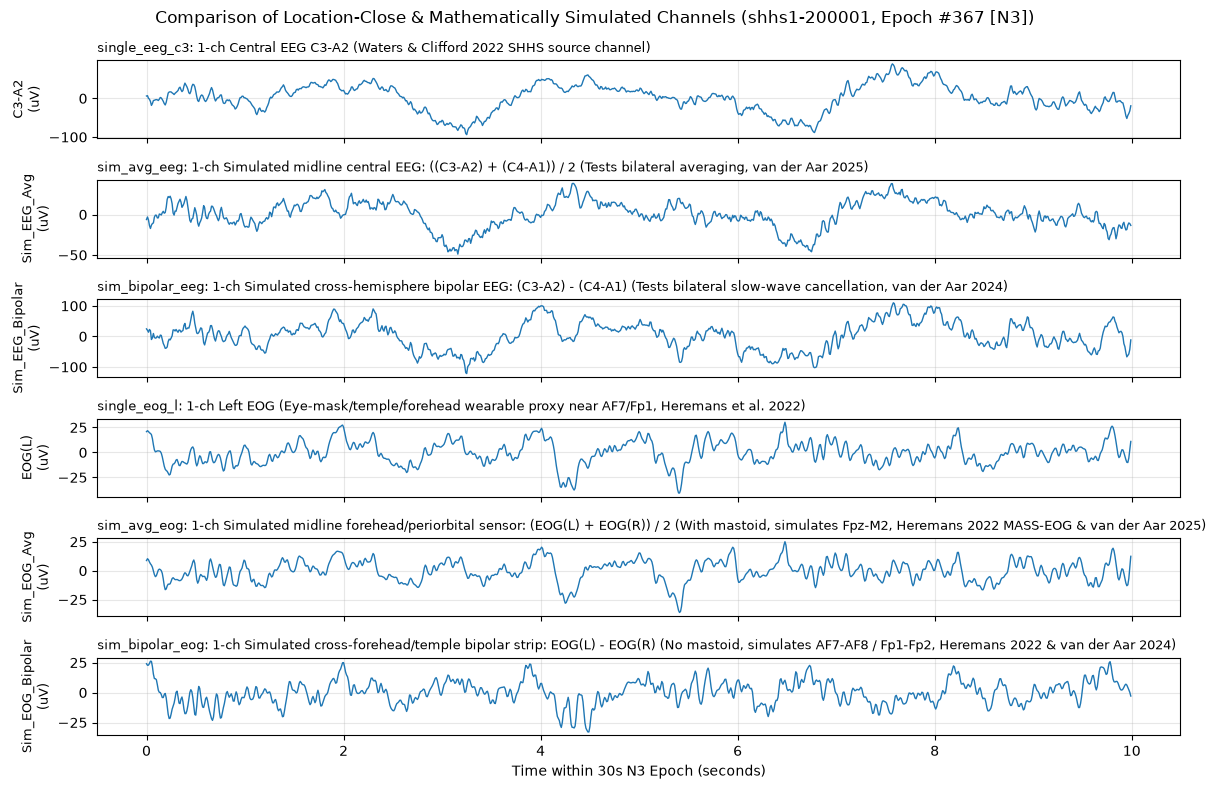

In [5]:
# Visualize a 10-second window of an N3 (Slow-Wave Sleep) epoch across Location-Close vs. Mathematically Simulated channels
n3_indices = np.where(sample_subj["labels"] == 3)[0]
ep_idx = int(n3_indices[len(n3_indices) // 2]) if len(n3_indices) > 0 else 0
t_sec = np.linspace(0, 10, 1000, endpoint=False)  # First 10 seconds (1000 samples at 100 Hz)

demo_keys = [
    "single_eeg_c3",
    "sim_avg_eeg",
    "sim_bipolar_eeg",
    "single_eog_l",
    "sim_avg_eog",
    "sim_bipolar_eog",
]

fig, axes = plt.subplots(len(demo_keys), 1, figsize=(12, 8), sharex=True)
for ax, key in zip(axes, demo_keys):
    x_uv, ch_names = apply_channel_config(sample_subj, shhs_configs[key], normalize=False)
    ax.plot(t_sec, x_uv[ep_idx, 0, :1000], linewidth=1.0)
    ax.set_ylabel(f"{ch_names[0]}\n(uV)", fontsize=9)
    ax.set_title(f"{key}: {shhs_configs[key]['description']}", fontsize=9.5, loc="left")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time within 30s N3 Epoch (seconds)")
fig.suptitle(f"Comparison of Location-Close & Mathematically Simulated Channels ({sample_subj['subject_id']}, Epoch #{ep_idx} [N3])", fontsize=12)
fig.tight_layout()
plt.show()

---
## Step 3: TinySleepNet Architecture (`use_context=False` & `use_context=True` Ready to Toggle)

Let's instantiate `TinySleepNet` in both **Model A (`use_context=False`, Context-Blind CNN)** and **Model B (`use_context=True`, Context-Aware CNN + LSTM)** modes and verify forward pass tensor shapes and parameter counts.

In [6]:
for ctx_mode in (False, True):
    model = build_tinysleepnet_from_config(base_config, in_channels=1, use_context_override=ctx_mode)
    n_params_total = sum(p.numel() for p in model.parameters())
    n_params_cnn = sum(p.numel() for p in model.feature_extractor.parameters())
    n_params_head = sum(p.numel() for p in model.classifier.parameters())
    
    if not ctx_mode:
        dummy_in = torch.randn(4, 1, 3000)
    else:
        dummy_in = torch.randn(2, 20, 1, 3000)  # Batch=2, Seq_Len=20, C=1, Samples=3000
    dummy_out = model(dummy_in)
    print(
        f"TinySleepNet (use_context={str(ctx_mode):5s}) | "
        f"Input: {tuple(dummy_in.shape)} -> Output Logits: {tuple(dummy_out.shape)} | "
        f"feat_dim={model.feat_dim:,} | Params: Total={n_params_total:,} (CNN={n_params_cnn:,}, Head={n_params_head:,})"
    )

TinySleepNet (use_context=False) | Input: (4, 1, 3000) -> Output Logits: (4, 5) | feat_dim=1,920 | Params: Total=410,245 (CNN=400,640, Head=9,605)
TinySleepNet (use_context=True ) | Input: (2, 20, 1, 3000) -> Output Logits: (2, 20, 5) | feat_dim=1,920 | Params: Total=1,450,885 (CNN=400,640, Head=1,050,245)


---
## Step 4: Subject-Independent 10-Fold Cross-Validation & Training (`src/training/trainer.py`)

First, we generate (or verify) the strict **subject-independent 10-fold CV split** (`data/splits/shhs_10fold_splits.json`), where each fold uses **80% of subjects for Training**, **10% for Validation**, and **10% for Test**.

### Strict Settings-Verified Fold Caching & Resume
- **Per-Fold Caching:** As soon as each fold finishes, its model checkpoint (`.pt`) and complete evaluation & hypnogram results (`results/<run_dir>/folds/<config>/fold_<XX>.json` and `results/<run_dir>/metrics_<config>.json`) are saved to disk along with a deterministic `settings_signature`.
- **Strict Settings Verification (`RESUME_FROM_SAVED = True`):**
  - A cached fold is **only** loaded and reused when the current run matches the saved fold's `settings_signature` (exact cohort split hash, channel configuration, `USE_CONTEXT`, `CLASS_WEIGHT_MODE`, `BATCH_SIZE`, `MAX_EPOCHS`, and `EARLY_STOPPING_PATIENCE`).
  - Furthermore, `get_experiment_results_dir(...)` creates a dedicated subfolder under `results/` for each distinct setting combination (e.g., `results/shhs1_healthy_n1771_ctxTrue_wsqrt_bs32_ep100_pat20/`), so toggling between `CLASS_WEIGHT_MODE = "sqrt"` and `"tinysleepnet"` keeps both runs intact!

In [7]:
split_file = PROJECT_ROOT / base_config["paths"]["splits_dir"] / "shhs_10fold_splits.json"
splits = ensure_subject_cv_splits(
    subject_ids=[r["subject_id"] for r in all_records],
    split_path=split_file,
    n_folds=10,
    seed=int(base_config["seed"]),
)

df_splits = pd.DataFrame([
    {
        "Fold": s["fold"],
        "N_Train (80%)": len(s["train"]),
        "N_Val (10%)": len(s["val"]),
        "N_Test (10%)": len(s["test"]),
        "Test_Preview": ", ".join(s["test"][:3]) + (" ..." if len(s["test"]) > 3 else ""),
    }
    for s in splits
])
display(df_splits)

,Fold,N_Train (80%),N_Val (10%),N_Test (10%),Test_Preview
0,0,1390,174,174,"shhs1-200058, shhs1-200079, shhs1-200129 ..."
1,1,1390,174,174,"shhs1-200004, shhs1-200039, shhs1-200052 ..."
2,2,1390,174,174,"shhs1-200034, shhs1-200042, shhs1-200046 ..."
3,3,1390,174,174,"shhs1-200001, shhs1-200008, shhs1-200041 ..."
4,4,1390,174,174,"shhs1-200033, shhs1-200073, shhs1-200082 ..."
5,5,1390,174,174,"shhs1-200017, shhs1-200021, shhs1-200036 ..."
6,6,1390,174,174,"shhs1-200053, shhs1-200068, shhs1-200127 ..."
7,7,1391,173,174,"shhs1-200010, shhs1-200051, shhs1-200055 ..."
8,8,1392,173,173,"shhs1-200044, shhs1-200091, shhs1-200105 ..."
9,9,1391,174,173,"shhs1-200019, shhs1-200093, shhs1-200109 ..."


In [8]:
# ============================================================================
# Experiment Control Panel (10-Fold Cross-Validation with Settings-Verified Caching)
# ============================================================================
USE_CONTEXT = True                # True = Model B (Context-Aware CNN + 20-epoch LSTM); False = Model A (Context-Blind CNN)
CLASS_WEIGHT_MODE = "sqrt"        # Toggle: "sqrt" | "tinysleepnet" ([1, 1.5, 1, 1, 1]) | "balanced" | False
BATCH_SIZE = 32                   # 32 sequences x 20 epochs = 640 epochs per gradient update
MAX_EPOCHS = 100                  # Maximum training epochs per fold
EARLY_STOPPING_PATIENCE = 20      # Stop fold after 20 epochs without val_macro_f1 improvement
MAX_FOLDS = 10                    # 10 = Full 10-fold subject-independent CV
RESUME_FROM_SAVED = True          # True = Load completed folds ONLY if settings_signature matches 100%
FORCE_RETRAIN = False             # Set to True only to force overwriting matching cached folds

# Target EEG channel configuration(s):
#   - ["dual_eeg"]        -> Both C4-A1 and C3-A2 together (2 channels)
#   - ["single_eeg_c4"]   -> Single C4-A1 only (1 channel)
#   - ["single_eeg_c3"]   -> Single C3-A2 only (1 channel)
#   - ["dual_eeg", "single_eeg_c4", "single_eeg_c3"] -> Train all 3 sequentially
SELECTED_CONFIG_NAMES = ["dual_eeg"]

results_dir = get_experiment_results_dir(
    root_dir=PROJECT_ROOT,
    base_config=base_config,
    n_subjects=len(all_records),
    use_context=USE_CONTEXT,
    class_weight_mode=CLASS_WEIGHT_MODE,
    batch_size=BATCH_SIZE,
    max_epochs=MAX_EPOCHS,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
)
print(f"Active Experiment Results Directory: {results_dir}")

ablation_results = {}
ablation_summaries = {}

for cfg_name in SELECTED_CONFIG_NAMES:
    cfg_spec = shhs_configs[cfg_name]
    print(f"\n{'='*78}")
    print(f"Config: {cfg_name} ({cfg_spec['description']})")
    print(f"{'='*78}")
    res = run_cross_validation_for_config(
        all_records=all_records,
        splits=splits,
        channel_config=cfg_spec,
        base_config=base_config,
        config_name=cfg_name,
        use_context_override=USE_CONTEXT,
        max_epochs_override=MAX_EPOCHS,
        class_weight_mode_override=CLASS_WEIGHT_MODE,
        batch_size_override=BATCH_SIZE,
        early_stopping_patience_override=EARLY_STOPPING_PATIENCE,
        max_folds=MAX_FOLDS,
        results_dir=results_dir,
        resume=RESUME_FROM_SAVED,
        force_retrain=FORCE_RETRAIN,
        verbose=True,
    )
    ablation_results[cfg_name] = res
    ablation_summaries[cfg_name] = res["aggregated_metrics"]

# Save combined CSV summary table to disk
df_ablation_summary = metrics_summary_to_dataframe(ablation_summaries)
summary_csv_path = results_dir / "ablation_summary_10fold.csv"
df_ablation_summary.to_csv(summary_csv_path, index=False)
print(f"\nAll results saved to {results_dir} (Summary CSV: {summary_csv_path})")

Active Experiment Results Directory: /home/uclab-guest-thesis/Documents/Benno_Hahn_BT_26WS/Thesis_Benno_Hahn/Automated-Sleep-Staging-Wearable-EEG-Channel-Simulation/results/shhs1_healthy_n1738_ctxTrue_wsqrt_bs32_ep100_pat20

Config: dual_eeg (2-ch Bilateral Central EEG (C4-A1, C3-A2))


KeyboardInterrupt: 

---
## Step 5: Standardized Evaluation Metrics (Markov et al., 2025 & van der Aar et al., 2025)

> **Tip for New Sessions / Different Computers:**
> If you open this notebook on another computer or in a new session after the 10 folds have been saved in `results/`, you do **not** need to run Step 4 again—running the cell below automatically loads `ablation_results` and `ablation_summaries` directly from `results/`!

We now inspect and save:
1. **Overall & Per-Stage Epoch Classification Metrics** (Multiclass Cohen's $\kappa$, Multiclass MCC, Macro-F1, Weighted-F1, Micro vs. Macro averages, and stage-specific F1/SE/PPV/MCC).
2. **Row-Normalized Confusion Matrices** (`mean ± SD` across test folds).
3. **Whole-Night Clinical Sleep Architecture Parameters** (`TST`, `SE%`, `SOL`, `WASO`, stage durations) and **Bland–Altman** agreement plots + full-night hypnogram comparisons.

In [ ]:
# Automatically load from disk if opening the notebook in a fresh session without running Step 4
if "USE_CONTEXT" not in globals():
    USE_CONTEXT = True
if "CLASS_WEIGHT_MODE" not in globals():
    CLASS_WEIGHT_MODE = "sqrt"
if "BATCH_SIZE" not in globals():
    BATCH_SIZE = 32
if "MAX_EPOCHS" not in globals():
    MAX_EPOCHS = 100
if "EARLY_STOPPING_PATIENCE" not in globals():
    EARLY_STOPPING_PATIENCE = 20
if "SELECTED_CONFIG_NAMES" not in globals():
    SELECTED_CONFIG_NAMES = ["dual_eeg"]
if "results_dir" not in globals():
    n_subj_est = len(all_records) if "all_records" in globals() else 1771
    results_dir = get_experiment_results_dir(
        root_dir=PROJECT_ROOT,
        base_config=base_config,
        n_subjects=n_subj_est,
        use_context=USE_CONTEXT,
        class_weight_mode=CLASS_WEIGHT_MODE,
        batch_size=BATCH_SIZE,
        max_epochs=MAX_EPOCHS,
        early_stopping_patience=EARLY_STOPPING_PATIENCE,
    )

if not globals().get("ablation_results"):
    print(f"Loading saved results from {results_dir} ...")
    ablation_results, ablation_summaries = load_saved_ablation_results(results_dir, SELECTED_CONFIG_NAMES)

df_ablation_summary = metrics_summary_to_dataframe(ablation_summaries)
display(df_ablation_summary)

In [ ]:
# Plot & Save Normalized Confusion Matrices (mean +- SD across folds) for each evaluated configuration
active_cfgs = [c for c in SELECTED_CONFIG_NAMES if c in ablation_summaries]
n_cfgs = len(active_cfgs)
ncols = min(3, max(1, n_cfgs))
nrows = (n_cfgs + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 5.2 * nrows))
axes_flat = np.atleast_1d(axes).ravel()

for idx, cfg_name in enumerate(active_cfgs):
    summ = ablation_summaries[cfg_name]
    mean_cm = np.array(summ["mean_confusion_matrix_norm"])
    std_cm = np.array(summ["std_confusion_matrix_norm"])
    plot_normalized_confusion_matrix(
        mean_norm_cm=mean_cm,
        std_norm_cm=std_cm,
        title=f"{cfg_name} (κ={summ['pooled_metrics']['kappa']:.2f}, {ablation_results[cfg_name]['n_folds_run']} folds)",
        ax=axes_flat[idx],
    )

for idx in range(n_cfgs, len(axes_flat)):
    axes_flat[idx].axis("off")

fig.suptitle("Row-Normalized Confusion Matrices (Mean ± SD Across Test Folds)", fontsize=14)
fig.tight_layout()
cm_fig_path = results_dir / "figures" / "confusion_matrices_grid.png"
cm_fig_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(cm_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved confusion matrices figure to {cm_fig_path}")

In [ ]:
# Clinical Sleep Architecture Agreement Table & Hypnogram / Bland-Altman Visualization
target_cfg = active_cfgs[0]
clin_agree = ablation_results[target_cfg]["pooled_clinical_agreement"]
df_clinical = pd.DataFrame.from_dict(clin_agree, orient="index")
clin_csv_path = results_dir / f"clinical_agreement_{target_cfg}.csv"
df_clinical.to_csv(clin_csv_path)
print(f"Whole-Night Clinical Sleep Parameter Agreement for '{target_cfg}' (saved to {clin_csv_path}):")
display(df_clinical.round(2))

# Collect all test subject hypnograms for target_cfg
test_subject_records = [
    subj_rec
    for fold_out in ablation_results[target_cfg]["folds"]
    for subj_rec in fold_out["test_per_subject"]
]

if test_subject_records:
    first_test = test_subject_records[0]
    hyp_fig_path = results_dir / "figures" / f"hypnogram_{target_cfg}_{first_test['subject_id']}.png"
    plot_hypnogram_comparison(
        y_true=first_test["y_true"],
        y_pred=first_test["y_pred"],
        subject_id=first_test["subject_id"],
        config_name=target_cfg,
        save_path=hyp_fig_path,
    )
    plt.show()

    if len(test_subject_records) >= 2:
        ba_fig_path = results_dir / "figures" / f"bland_altman_{target_cfg}.png"
        plot_bland_altman_grid(
            subject_records=test_subject_records,
            parameters=["TST_min", "SE_pct", "SOL_min", "WASO_min"],
            title=f"Bland-Altman Agreement — {target_cfg} (N={len(test_subject_records)} Test Nights)",
            save_path=ba_fig_path,
        )
        plt.show()